In [1]:
# import packages

import os
import time as tt
import math
import re
from collections import Counter
import glob

import numpy as np
import pandas as pd

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.gridspec import GridSpec

import cmcrameri.cm as cmc

import roboarmanalysis as ra
import trackpy as tp

from scipy.stats import circmean, skew
from scipy.signal import correlate
from scipy.optimize import curve_fit
from statsmodels import robust

%matplotlib widget

import numpy as np
from scipy.stats import circmean, circstd, skew, kurtosis
from scipy.signal import argrelextrema
from scipy.ndimage import gaussian_filter1d


# Helper: compute energy landscape
def compute_energy(data, bins):
    p, edges = np.histogram(data, bins=bins, density=True)
    E = np.where(p == 0, np.nan, -np.log(p + 1e-12))
    centers = 0.5 * (edges[:-1] + edges[1:])
    return centers, E



def multiple_formatter(denominator=2, number=np.pi, latex='\pi'):
    def gcd(a, b):
        while b:
            a, b = b, a%b
        return a
    def _multiple_formatter(x, pos):
        den = denominator
        num = int(np.rint(den*x/number))
        com = gcd(num,den)
        (num,den) = (int(num/com),int(den/com))
        if den==1:
            if num==0:
                return r'$0$'
            if num==1:
                return r'$%s$'%latex
            elif num==-1:
                return r'$-%s$'%latex
            else:
                return r'$%s%s$'%(num,latex)
        else:
            if num==1:
                return r'$\frac{%s}{%s}$'%(latex,den)
            elif num==-1:
                return r'$\frac{-%s}{%s}$'%(latex,den)
            else:
                return r'$\frac{%s%s}{%s}$'%(num,latex,den)
    return _multiple_formatter

trimmed_cmap = lambda name, n, lo=0.2, hi=0.8: \
    plt.colormaps[name](np.linspace(lo, hi, n))
colormap = plt.colormaps.get_cmap('cmc.vik').resampled(14)

import matplotlib as mpl
import matplotlib.pyplot as plt

# --- General figure scaling for Jupyter ---
mpl.rcParams.update({
    "figure.dpi": 150,          # lower DPI → smaller figures on screen
    "figure.figsize": (5, 3),   # default size in inches (width, height)
    "font.size": 10,            # base font size
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
})

import numpy as np
import matplotlib.pyplot as plt
import types

# ---------- helpers ----------
def _set_pi_ticks(ax):
    ax.set_xticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
    ax.set_xticklabels([r'$-\pi$', r'$-\pi/2$', r'$0$', r'$\pi/2$', r'$\pi$'])

def _energy_amp_and_curve(phi, bins):
    centers, E = compute_energy(phi, bins=bins)
    f = np.isfinite(E)
    if not f.any():
        return np.nan, centers, E, 0
    amp = float(np.nanmax(E[f]) - np.nanmin(E[f]))
    return amp, centers, E, int(f.sum())

def _radius_ok(m, pid, min_R=400.0):
    if not hasattr(m, "particle_data") or m.particle_data is None:
        return False
    R = None
    df = m.particle_data
    if "R" not in getattr(df, "columns", []):
        return False
    # try index first
    if pid in getattr(df, "index", []):
        R = df.loc[pid, "R"]
    # fallback: a 'group' column
    elif "group" in df.columns:
        row = df.loc[df["group"] == pid]
        if not row.empty:
            R = row.iloc[0]["R"]
    try:
        return float(R) > float(min_R)
    except Exception:
        return False

def _rot_end_ok(m, pid, rot_phase='rot-both', tol=2*np.pi):
    """
    Accept if |Δφ| ≤ tol over the rot_phase. Prefer m.trajectories[rot_phase][pid],
    else fall back to locs within protocol window.
    """
    # A) try precomputed trajectory
    try:
        s = m.trajectories[rot_phase][pid].dropna()
        v = np.asarray(s.values, float)
        if v.size >= 2:
            dv = np.unwrap(v)[-1] - np.unwrap(v)[0]
            return np.isfinite(dv) and (abs(dv) <= float(tol))
    except Exception:
        pass

    # B) fallback via locs
    if not hasattr(m, "locs") or "phi" not in m.locs.columns or rot_phase not in m.protocol:
        return False
    locs = m.locs
    if "t" not in locs.columns:
        if not hasattr(m, "_average_tpf"):
            return False
        locs = locs.copy()
        locs["t"] = locs["frame"] * float(m._average_tpf)
    t0, t1 = m.protocol[rot_phase][:2]
    df = locs[(locs["group"] == pid) & (locs["t"] >= t0) & (locs["t"] < t1)]
    if df.empty:
        return False
    v = np.asarray(df["phi"], float)
    if v.size < 2:
        return False
    dv = np.unwrap(v)[-1] - np.unwrap(v)[0]
    return np.isfinite(dv) and (abs(dv) <= float(tol))

# ---------- main method (binds to each m): whitelist only + ALL three filters ----------
def _get_flat_particles(self,
                        threshold_kbt=2.5,
                        phase='umbrella',
                        bins=None,
                        rot_phase='rot-both',
                        rot_end_tol=2*np.pi,
                        radius_min=400.0):
    """
    Return and store m.flat_particles consisting ONLY of whitelist particles that satisfy:
      1) flat umbrella energy: max(E)-min(E) <= threshold_kbt (kBT units),
      2) rot-both end constraint: |Δφ| <= rot_end_tol (default 2π) over rot_phase,
      3) radius filter: R > radius_min from m.particle_data['R'].
    No other fields on m are modified.
    """
    # strict whitelist requirement
    if not hasattr(self, "whitelist") or self.whitelist is None or len(self.whitelist) == 0:
        raise AttributeError("m.whitelist must be set and non-empty.")

    if not hasattr(self, "locs") or "group" not in self.locs.columns or "phi" not in self.locs.columns:
        raise AttributeError("m.locs must exist with columns ['group','phi','frame'].")
    if not hasattr(self, "protocol") or phase not in self.protocol:
        raise AttributeError(f"m.protocol['{phase}'] is required.")
    if not hasattr(self, "_average_tpf"):
        raise AttributeError("m._average_tpf is required to derive time from frames.")

    # time column for phase slicing
    locs = self.locs.copy()
    if "t" not in locs.columns:
        locs["t"] = locs["frame"] * float(self._average_tpf)

    # bins exactly like your plots
    if bins is None:
        bins = np.deg2rad(np.arange(-180, 185, 5))

    # umbrella phase window
    t0, t1 = self.protocol[phase][:2]
    mask_phase = (locs["t"] >= t0) & (locs["t"] < t1)

    selected = []
    whitelist = sorted({int(p) for p in self.whitelist})
    present = set(int(g) for g in np.unique(locs["group"]))

    for pid in whitelist:
        if pid not in present:
            continue
        # radius check first (cheap)
        if not _radius_ok(self, pid, min_R=radius_min):
            continue
        # umbrella energy amplitude on whitelist particle
        df = locs[(locs["group"] == pid) & mask_phase]
        if df.empty:
            continue
        amp, _, E, nbin = _energy_amp_and_curve(df["phi"].to_numpy(), bins=bins)
        if not (np.isfinite(amp) and nbin >= 6 and amp <= float(threshold_kbt)):
            continue
        # trajectory end constraint on rot-both
        if not _rot_end_ok(self, pid, rot_phase=rot_phase, tol=rot_end_tol):
            continue
        selected.append(pid)

    self.flat_particles = selected
    return selected

# ---------- bind (idempotent) ----------
def bind_get_flat_particles(m_list):
    for _m in m_list:
        _m.get_flat_particles = types.MethodType(_get_flat_particles, _m)

# # ---------- overview plot: one subplot per m, overlay only the accepted flats ----------
def plot_flat_energy_overview(m_list,
                              threshold_kbt=2.5,
                              phase='umbrella',
                              rot_phase='rot-both',
                              rot_end_tol=2*np.pi,
                              radius_min=400.0):
    """
    Detects flat particles with ALL calibration filters per m (whitelist only),
    then draws one subplot per m with all accepted min-shifted energy landscapes.
    """
    bind_get_flat_particles(m_list)

    n = len(m_list)
    ncols = int(np.ceil(np.sqrt(n)))
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.4*ncols, 3.2*nrows))
    axes = np.atleast_1d(axes).ravel()

    bins = np.deg2rad(np.arange(-180, 185, 5))

    for ax, m in zip(axes, m_list):
        try:
            flats = m.get_flat_particles(threshold_kbt=threshold_kbt,
                                         phase=phase,
                                         bins=bins,
                                         rot_phase=rot_phase,
                                         rot_end_tol=rot_end_tol,
                                         radius_min=radius_min)
        except Exception as e:
            ax.text(0.5, 0.5, f"Error:\n{e}", ha='center', va='center', fontsize=8)
            ax.set_axis_off()
            continue

        if len(flats) == 0:
            ax.text(0.5, 0.5, "no eligible particles", ha='center', va='center', fontsize=9)
            ax.set_title(getattr(m, "name", "m"), fontsize=10)
            ax.set_xlim(-np.pi, np.pi)
            _set_pi_ticks(ax)
            continue

        # umbrella window for curves
        locs = m.locs.copy()
        if "t" not in locs.columns:
            locs["t"] = locs["frame"] * float(m._average_tpf)
        t0, t1 = m.protocol[phase][:2]
        mask_phase = (locs["t"] >= t0) & (locs["t"] < t1)

        # overlay min-shifted energies
        for pid in flats:
            df = locs[(locs["group"] == pid) & mask_phase]
            if df.empty:
                continue
            _, centers, E, _ = _energy_amp_and_curve(df["phi"].to_numpy(), bins=bins)
            if not np.isfinite(E).any():
                continue
            Es = E - np.nanmin(E)
            ax.plot(centers, Es, lw=1.2, color='k', alpha = 0.5)

        ax.set_title(getattr(m, "name", "m"), fontsize=10)
        ax.set_xlim(-np.pi, np.pi); _set_pi_ticks(ax)
        ax.set_xlabel(r'$\varphi$  / rad'); ax.set_ylabel(r'$V$ / $k_BT$')


    for j in range(len(m_list), len(axes)):
        axes[j].set_axis_off()

    plt.tight_layout()
    plt.show()




In [2]:
# import packages

import os
import time as tt
import math
import re
from collections import Counter
import glob

import numpy as np
import pandas as pd

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.gridspec import GridSpec
from pathlib import Path
import cmcrameri.cm as cmc

import roboarmanalysis as ra
import trackpy as tp

from scipy.stats import circmean, skew
from scipy.signal import correlate
from scipy.optimize import curve_fit
from statsmodels import robust

%matplotlib widget

import numpy as np
from scipy.stats import circmean, circstd, skew, kurtosis
from scipy.signal import argrelextrema
from scipy.ndimage import gaussian_filter1d

import os
import time as tt
import math
import re
from collections import Counter
import glob

import numpy as np
import pandas as pd
from tqdm.auto import tqdm 

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.gridspec import GridSpec

import cmcrameri.cm as cmc


import trackpy as tp

from scipy.stats import circmean, skew
from scipy.signal import correlate
from scipy.optimize import curve_fit
from statsmodels import robust

import numpy as np
from scipy.stats import circmean, circstd, skew, kurtosis
from scipy.signal import argrelextrema
from scipy.ndimage import gaussian_filter1d

import importlib
%load_ext autoreload
%autoreload 2

import roboarmanalysis as ra
from tqdm.auto import tqdm
from contextlib import contextmanager


# Helper: compute energy landscape
def compute_energy(data, bins):
    p, edges = np.histogram(data, bins=bins, density=True)
    E = np.where(p == 0, np.nan, -np.log(p + 1e-12))
    centers = 0.5 * (edges[:-1] + edges[1:])
    return centers, E



def multiple_formatter(denominator=2, number=np.pi, latex='\pi'):
    def gcd(a, b):
        while b:
            a, b = b, a%b
        return a
    def _multiple_formatter(x, pos):
        den = denominator
        num = int(np.rint(den*x/number))
        com = gcd(num,den)
        (num,den) = (int(num/com),int(den/com))
        if den==1:
            if num==0:
                return r'$0$'
            if num==1:
                return r'$%s$'%latex
            elif num==-1:
                return r'$-%s$'%latex
            else:
                return r'$%s%s$'%(num,latex)
        else:
            if num==1:
                return r'$\frac{%s}{%s}$'%(latex,den)
            elif num==-1:
                return r'$\frac{-%s}{%s}$'%(latex,den)
            else:
                return r'$\frac{%s%s}{%s}$'%(num,latex,den)
    return _multiple_formatter

trimmed_cmap = lambda name, n, lo=0.2, hi=0.8: \
    plt.colormaps[name](np.linspace(lo, hi, n))
colormap = plt.colormaps.get_cmap('cmc.vik').resampled(14)

import matplotlib as mpl
import matplotlib.pyplot as plt

# --- General figure scaling for Jupyter ---
mpl.rcParams.update({
    "figure.dpi": 50,          # lower DPI → smaller figures on screen
    "figure.figsize": (5, 3),   # default size in inches (width, height)
    "font.size": 10,            # base font size
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
})

import numpy as np
import matplotlib.pyplot as plt
import types

# ---------- helpers ----------
def _set_pi_ticks(ax):
    ax.set_xticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
    ax.set_xticklabels([r'$-\pi$', r'$-\pi/2$', r'$0$', r'$\pi/2$', r'$\pi$'])

def _energy_amp_and_curve(phi, bins):
    centers, E = compute_energy(phi, bins=bins)
    f = np.isfinite(E)
    if not f.any():
        return np.nan, centers, E, 0
    amp = float(np.nanmax(E[f]) - np.nanmin(E[f]))
    return amp, centers, E, int(f.sum())

def _radius_ok(m, pid, min_R=400.0):
    if not hasattr(m, "particle_data") or m.particle_data is None:
        return False
    R = None
    df = m.particle_data
    if "R" not in getattr(df, "columns", []):
        return False
    # try index first
    if pid in getattr(df, "index", []):
        R = df.loc[pid, "R"]
    # fallback: a 'group' column
    elif "group" in df.columns:
        row = df.loc[df["group"] == pid]
        if not row.empty:
            R = row.iloc[0]["R"]
    try:
        return float(R) > float(min_R)
    except Exception:
        return False

def _rot_end_ok(m, pid, rot_phase='rot-both', tol=2*np.pi):
    """
    Accept if |Δφ| ≤ tol over the rot_phase. Prefer m.trajectories[rot_phase][pid],
    else fall back to locs within protocol window.
    """
    # A) try precomputed trajectory
    try:
        s = m.trajectories[rot_phase][pid].dropna()
        v = np.asarray(s.values, float)
        if v.size >= 2:
            dv = np.unwrap(v)[-1] - np.unwrap(v)[0]
            return np.isfinite(dv) and (abs(dv) <= float(tol))
    except Exception:
        pass

    # B) fallback via locs
    if not hasattr(m, "locs") or "phi" not in m.locs.columns or rot_phase not in m.protocol:
        return False
    locs = m.locs
    if "t" not in locs.columns:
        if not hasattr(m, "_average_tpf"):
            return False
        locs = locs.copy()
        locs["t"] = locs["frame"] * float(m._average_tpf)
    t0, t1 = m.protocol[rot_phase][:2]
    df = locs[(locs["group"] == pid) & (locs["t"] >= t0) & (locs["t"] < t1)]
    if df.empty:
        return False
    v = np.asarray(df["phi"], float)
    if v.size < 2:
        return False
    dv = np.unwrap(v)[-1] - np.unwrap(v)[0]
    return np.isfinite(dv) and (abs(dv) <= float(tol))

# ---------- main method (binds to each m): whitelist only + ALL three filters ----------
def _get_flat_particles(self,
                        threshold_kbt=2.5,
                        phase='umbrella',
                        bins=None,
                        rot_phase='rot-both',
                        rot_end_tol=2*np.pi,
                        radius_min=400.0):
    """
    Return and store m.flat_particles consisting ONLY of whitelist particles that satisfy:
      1) flat umbrella energy: max(E)-min(E) <= threshold_kbt (kBT units),
      2) rot-both end constraint: |Δφ| <= rot_end_tol (default 2π) over rot_phase,
      3) radius filter: R > radius_min from m.particle_data['R'].
    No other fields on m are modified.
    """
    # strict whitelist requirement
    if not hasattr(self, "whitelist") or self.whitelist is None or len(self.whitelist) == 0:
        raise AttributeError("m.whitelist must be set and non-empty.")

    if not hasattr(self, "locs") or "group" not in self.locs.columns or "phi" not in self.locs.columns:
        raise AttributeError("m.locs must exist with columns ['group','phi','frame'].")
    if not hasattr(self, "protocol") or phase not in self.protocol:
        raise AttributeError(f"m.protocol['{phase}'] is required.")
    if not hasattr(self, "_average_tpf"):
        raise AttributeError("m._average_tpf is required to derive time from frames.")

    # time column for phase slicing
    locs = self.locs.copy()
    if "t" not in locs.columns:
        locs["t"] = locs["frame"] * float(self._average_tpf)

    # bins exactly like your plots
    if bins is None:
        bins = np.deg2rad(np.arange(-180, 185, 5))

    # umbrella phase window
    t0, t1 = self.protocol[phase][:2]
    mask_phase = (locs["t"] >= t0) & (locs["t"] < t1)

    selected = []
    whitelist = sorted({int(p) for p in self.whitelist})
    present = set(int(g) for g in np.unique(locs["group"]))

    for pid in whitelist:
        if pid not in present:
            continue
        # radius check first (cheap)
        if not _radius_ok(self, pid, min_R=radius_min):
            continue
        # umbrella energy amplitude on whitelist particle
        df = locs[(locs["group"] == pid) & mask_phase]
        if df.empty:
            continue
        amp, _, E, nbin = _energy_amp_and_curve(df["phi"].to_numpy(), bins=bins)
        if not (np.isfinite(amp) and nbin >= 6 and amp <= float(threshold_kbt)):
            continue
        # trajectory end constraint on rot-both
        if not _rot_end_ok(self, pid, rot_phase=rot_phase, tol=rot_end_tol):
            continue
        selected.append(pid)

    self.flat_particles = selected
    return selected

# ---------- bind (idempotent) ----------
def bind_get_flat_particles(m_list):
    for _m in m_list:
        _m.get_flat_particles = types.MethodType(_get_flat_particles, _m)

# ---------- overview plot: one subplot per m, overlay only the accepted flats ----------
def plot_flat_energy_overview(m_list,
                              threshold_kbt=2.5,
                              phase='umbrella',
                              rot_phase='rot-both',
                              rot_end_tol=2*np.pi,
                              radius_min=400.0):
    """
    Detects flat particles with ALL calibration filters per m (whitelist only),
    then draws one subplot per m with all accepted min-shifted energy landscapes.
    """
    bind_get_flat_particles(m_list)

    n = len(m_list)
    ncols = int(np.ceil(np.sqrt(n)))
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.4*ncols, 3.2*nrows))
    axes = np.atleast_1d(axes).ravel()

    bins = np.deg2rad(np.arange(-180, 185, 5))

    for ax, m in zip(axes, m_list):
        try:
            flats = m.get_flat_particles(threshold_kbt=threshold_kbt,
                                         phase=phase,
                                         bins=bins,
                                         rot_phase=rot_phase,
                                         rot_end_tol=rot_end_tol,
                                         radius_min=radius_min)
        except Exception as e:
            ax.text(0.5, 0.5, f"Error:\n{e}", ha='center', va='center', fontsize=8)
            ax.set_axis_off()
            continue

        if len(flats) == 0:
            ax.text(0.5, 0.5, "no eligible particles", ha='center', va='center', fontsize=9)
            ax.set_title(getattr(m, "name", "m"), fontsize=10)
            ax.set_xlim(-np.pi, np.pi)
            _set_pi_ticks(ax)
            continue

        # umbrella window for curves
        locs = m.locs.copy()
        if "t" not in locs.columns:
            locs["t"] = locs["frame"] * float(m._average_tpf)
        t0, t1 = m.protocol[phase][:2]
        mask_phase = (locs["t"] >= t0) & (locs["t"] < t1)

        # overlay min-shifted energies
        for pid in flats:
            df = locs[(locs["group"] == pid) & mask_phase]
            if df.empty:
                continue
            _, centers, E, _ = _energy_amp_and_curve(df["phi"].to_numpy(), bins=bins)
            if not np.isfinite(E).any():
                continue
            Es = E - np.nanmin(E)
            ax.plot(centers, Es, lw=1.2, color='k', alpha = 0.5)

        ax.set_title(getattr(m, "name", "m"), fontsize=10)
        ax.set_xlim(-np.pi, np.pi); _set_pi_ticks(ax)
        ax.set_xlabel(r'$\varphi$  / rad'); ax.set_ylabel(r'$V$ / $k_BT$')


    for j in range(len(m_list), len(axes)):
        axes[j].set_axis_off()

    plt.tight_layout()
    plt.show()



import re
from math import inf
from typing import Iterable

# Variant order for sorting (unknowns last)
_VARIANT_ORDER = {'A':0, 'B':1, 'C':2, 'D':3, 'E':4}

def assign_conditions(m) -> None:
    """
    Parse m's path/filename and write:
      m.stator_variant ∈ {'A','B','C','D','E'} (or None)
      m.bias_voltage_V : float (or None)
      m.time_halfcycle_s : float seconds (or None)
      m.source_path : str (best-guess source path/filename)
      m._detect_notes : str (human-readable summary)
    Side effects only. Returns None.

    All helpers are defined locally to keep the API surface minimal.
    """

    # -------- helpers (local only) --------
    def _path_of(obj) -> str:
        for a in ("path","filepath","file","filename","source","source_file",
                  "hdf5_path","hdf5","directory","dirpath"):
            v = getattr(obj, a, None)
            if isinstance(v, str) and v:
                return v
        for a in ("meta","info","attrs","props"):
            d = getattr(obj, a, None)
            if isinstance(d, dict):
                for k in ("path","filepath","file","filename","source","source_file",
                          "hdf5_path","hdf5","directory","dirpath"):
                    v = d.get(k)
                    if isinstance(v, str) and v:
                        return v
        return str(obj)

def purge_locscolumns(m, cols=None):
    LOC_COLUMNS_TO_DROP = ['photosm', 'photons', 'sx', 'sy', 'bg', 'lpx', 'lpy', 'ellipticity', 'net_gradient']    
    if cols is None:
        cols = LOC_COLUMNS_TO_DROP
    if hasattr(m, 'locs') and isinstance(m.locs, pd.DataFrame):
        drop = [c for c in cols if c in m.locs.columns]
        if drop:
            m.locs = m.locs.drop(columns=drop)



# -------- optional vik colormap (fallback to coolwarm) --------
try:
    import cmcrameri.cm as cmc
    _vik = cmc.vik
except Exception:
    _vik = plt.cm.get_cmap("coolwarm")
    cmc = None

# -------- style --------
PAPER_RC = {
    "text.usetex": False, "font.family": "DejaVu Sans", "mathtext.fontset": "dejavusans",
    "font.size": 8, "axes.labelsize": 7, "axes.titlesize": 8,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "figure.dpi": 180,
    "axes.linewidth": 0.6, "xtick.direction": "out", "ytick.direction": "out",
    "xtick.major.size": 2.0, "ytick.major.size": 2.0, "svg.fonttype": "none",
}
def _style_ax(ax, grey="0.25"):
    for s in ax.spines.values():
        s.set_color(grey); s.set_linewidth(0.6)
    ax.tick_params(length=2.0, width=0.6, colors=grey)
    ax.xaxis.label.set_color(grey); ax.yaxis.label.set_color(grey)
    ax.title.set_color(grey); ax.grid(False)

# ========= style (yours) =========
PAPER_RC = {
    "text.usetex": False,
    "font.family": "DejaVu Sans",
    "mathtext.fontset": "dejavusans",
    "font.size": 8,
    "axes.labelsize": 7,
    "axes.titlesize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "figure.dpi": 300,
    "axes.linewidth": 0.8,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.size": 2.0,
    "ytick.major.size": 2.0,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.size": 2.0,
    "ytick.major.size": 2.0,
    "svg.fonttype": "none",
}


import matplotlib as mpl
mpl.rcParams["figure.dpi"] = 100
mpl.rcParams["savefig.dpi"] = 300


def save_figure(
    fig,
    name="xxx",
    stator_variant="",
    save_directory=r"R:\_06_Umbrella_Sampling\02_Figures",
    dpi=300,
    tight=True,
    # overwrite=True,          # NEW: controls whether to overwrite or add _01, _02, ...
):
    """
    Save `fig` as PNG and SVG into `save_directory`.

    If overwrite=True (default):
        <stator_variant>__<name>.png/.svg   (existing files are overwritten)

    If overwrite=False:
        <stator_variant>__<name>_NN.png/.svg  with NN auto-incremented.
    """
    out_dir = Path(save_directory)
    out_dir.mkdir(parents=True, exist_ok=True)

    prefix = f"{stator_variant}__{name}" if stator_variant else name

    # if overwrite:
    stem = prefix

    png_path = out_dir / f"{stem}.png"
    svg_path = out_dir / f"{stem}.svg"

    bbox = "tight" if tight else None

    fig.savefig(png_path, dpi=dpi, bbox_inches=bbox, facecolor="white")
    fig.savefig(svg_path,        bbox_inches=bbox)

### Load and trim dataset

In [3]:
save_dir = Path(r"R:\_06_Umbrella_Sampling\01_Dataset\260707_L2ss\260707-fov01_01_DIFF_60s__L2ss-40nmCalibR_1xRef45Suc_1")

keywords = []
exclude_keywords = []

m_list_loaded = ra.load_multiple_measurements(
    save_dir,
    keywords=keywords,
    exclude_keywords=exclude_keywords,
)



 >>> y-coordinates are flipped to account for TIRFM geometry (now aligns with micromanager and picasso).
Filtered localizations for a fit uncertainty less than 100nm.
...protocol.txt file not found in R:\_06_Umbrella_Sampling\01_Dataset\260707_L2ss\260707-fov01_01_DIFF_60s__L2ss-40nmCalibR_1xRef45Suc_1.
Import the file with .get_protocol(path_to_your_txt_file)
Adding file: R:\_06_Umbrella_Sampling\01_Dataset\260707_L2ss\260707-fov01_01_DIFF_60s__L2ss-40nmCalibR_1xRef45Suc_1\260707-fov01_01_DIFF_60s__L2ss-40nmCalibR_1xRef45Suc_1_MMStack_Default.ome_locs_render_picked.hdf5


In [4]:
m_list = m_list_loaded


### Process dataset - assign phases, compute polar coordinates, trajectories

In [5]:
# Assign phases, convert to polar coordinates, compute trajectories
columns_to_drop = ['photosm', 'photons', 'sx', 'sy', 'bg', 'lpx', 'lpy', 'ellipticity', 'net_gradient']
allowed_missed_percentage = 20
dt_s = 0.005  # 5 ms acquisition


for idx, m in enumerate(m_list):
    m.protocol = {"diff": (0, 60)}
    m.protocol["all"] = (0, 60)
    m._has_protocol = True
    m._num_phases = len(m.protocol)

# ra.fit_circles_with_reference_measurement(m_list, m_list, particles=None)


for idx, m in enumerate(m_list):
    if hasattr(m, "protocol") and "all" in m.protocol:
        t0, t1 = m.protocol["all"]
        duration_s = t1 - t0
    else:
        duration_s = (m.locs["frame"].max() - m.locs["frame"].min() + 1) * dt_s

    expected_frames = duration_s / dt_s
    frame_threshold = (1 - allowed_missed_percentage / 100) * expected_frames


    counts = m.locs.groupby("group")["frame"].nunique()
    bl = counts[counts < frame_threshold].index.tolist()
    m.add_to_blacklist(bl, silent=True)
    purge_locscolumns(m, cols = columns_to_drop)
    
    print(str(idx) + ': ' + Path(m.path).name + ' ' + str(len(m.whitelist)) + ' particles.')



for idx, m in enumerate(m_list):
    m.fit_circles()
    m.polar_coordinates()
    m.calc_trajectories()


0: 260707-fov01_01_DIFF_60s__L2ss-40nmCalibR_1xRef45Suc_1_MMStack_Default.ome_locs_render_picked.hdf5 214 particles.
Fitting circles for whitelist:


  0%|          | 0/214 [00:00<?, ?it/s]

Phases:   0%|          | 0/2 [00:00<?, ?it/s]

  diff:   0%|          | 0/214 [00:00<?, ?it/s]

  all:   0%|          | 0/214 [00:00<?, ?it/s]

### Prepare Figure 1a - exemplary localization scatter plot and histograms

In [6]:
# STATE ANALYSIS of particles
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy.signal import find_peaks
from scipy.ndimage import gaussian_filter1d

# ───────────────────────── circular helpers ─────────────────────────
_TWOPI = 2.0*np.pi
def wrap_pi(a):
    return (a + np.pi) % _TWOPI - np.pi

def dphi(a, b):
    return wrap_pi(a - b)

def wrap_pi_len_pi(a):
    """Map any angle to an interval of length π (modulo-π axis)."""
    return ((wrap_pi(a) + np.pi/2) % np.pi) - np.pi/2

def axis_in_0_pi(a):
    """Return axis in [0, π)."""
    b = wrap_pi_len_pi(a)
    if np.isfinite(b) and b < 0:
        b += np.pi
    return b

def _ccw_mask(x, start, end):
    """
    Vectorized: True where angle x lies on the CCW arc from start→end.
    All args can be arrays or scalars; broadcasting applies.
    """
    s = wrap_pi(start); e = wrap_pi(end); xx = wrap_pi(x)
    w = wrap_pi(e - s); w = np.where(w >= 0, w, w + _TWOPI)
    d = wrap_pi(xx - s); d = np.where(d >= 0, d, d + _TWOPI)
    return d <= w

def ccw_span_to_intervals(start, end):
    """Represent CCW arc [start→end] as 1–2 intervals inside [-π, π] (for axvspan)."""
    s = wrap_pi(start); e = wrap_pi(end)
    if s <= e: return [(s, e)]
    return [(-np.pi, e), (s, np.pi)]

# ───────────────── tqdm helper ─────────────────
def _iter_progress(iterable, desc="Particles"):
    try:
        from tqdm.auto import tqdm
        return tqdm(iterable, desc=desc)
    except Exception:
        return iterable

# ───────────── histogram → energy ─────────────
def circ_hist(phi, bins=72):
    edges = np.linspace(-np.pi, np.pi, bins+1)
    p, _ = np.histogram(phi, bins=edges, density=True)
    centers = 0.5*(edges[:-1] + edges[1:])
    return centers, p, edges

def smooth_periodic(y, sigma_bins=1.0):
    n = len(y)
    pad = 3*int(np.ceil(sigma_bins))
    if pad == 0:
        return gaussian_filter1d(y, sigma=sigma_bins, mode='nearest')
    ypad = np.r_[y[-pad:], y, y[:pad]]
    ypad = gaussian_filter1d(ypad, sigma=sigma_bins, mode='nearest')
    return ypad[pad:pad+n]

def energy_unshifted(p, eps=1e-12):
    with np.errstate(divide='ignore'):
        return -np.log(p + eps)

# ───── wells + barriers (with diametric fallback) ─────
def find_wells(phi_all, bins=72, sigma_bins=1.0, prom_rel=0.15, min_sep=np.pi/2):
    C, P, edges = circ_hist(phi_all, bins=bins)
    Ps = smooth_periodic(P, sigma_bins=sigma_bins)

    if np.max(Ps) <= 0 or np.allclose(Ps, Ps[0]):
        return dict(C=C, Ps=Ps, E=None, mins=[], mins_idx=[], edges=edges, barriers=(np.nan, np.nan))

    E = energy_unshifted(Ps)

    # Peaks by prominence, then choose up to two highest (argpartition faster than full sort)
    cand, _ = find_peaks(Ps, prominence=np.max(Ps)*prom_rel)
    if cand.size:
        cand2 = cand[np.argsort(Ps[cand])[::-1][:2]]
    else:
        cand2 = np.array([], dtype=int)

    mins_idx = []
    for i in cand2:
        if not mins_idx:
            mins_idx.append(int(i))
        else:
            if np.abs(wrap_pi(C[i] - C[mins_idx[0]])) >= min_sep:
                mins_idx.append(int(i))
                break

    # diametric fallback
    if len(mins_idx) == 1:
        i0 = mins_idx[0]; phi0 = C[i0]; phi_op = wrap_pi(phi0 + np.pi)
        OCC_WIN, OCC_FRAC, OCC_ABS = np.deg2rad(25.0), 0.002, 3
        N = phi_all.size
        op_sel = np.abs(wrap_pi(phi_all - phi_op)) <= OCC_WIN
        if (np.count_nonzero(op_sel) >= max(OCC_ABS, int(np.ceil(OCC_FRAC*N)))):
            j_guess = int(np.argmin(np.abs(wrap_pi(C - phi_op))))
            n = Ps.size; neigh = [(j_guess-1) % n, j_guess, (j_guess+1) % n]
            j2 = neigh[int(np.argmax(Ps[neigh]))]
            if np.abs(wrap_pi(C[j2] - C[i0])) >= 0.9*min_sep:
                mins_idx.append(int(j2))

    mins = [C[i] for i in mins_idx]

    # barriers
    barriers = (np.nan, np.nan)
    if len(mins_idx) == 2:
        n = Ps.size; i1, i2 = sorted(mins_idx)
        arc12_P = Ps[i1:i2+1]
        arc21_P = np.r_[Ps[i2:], Ps[:i1+1]]
        j12 = i1 + int(np.argmin(arc12_P)) if arc12_P.size else None
        j21 = (i2 + int(np.argmin(arc21_P))) % n if arc21_P.size else None

        def _ok(j): return (j is not None) and (j not in (i1,i2))
        if _ok(j12) and _ok(j21):
            thb12, thb21 = C[j12], C[j21]
        else:
            arc12_E = E[i1:i2+1]; arc21_E = np.r_[E[i2:], E[:i1+1]]
            ib12 = i1 + int(np.nanargmax(arc12_E)) if arc12_E.size else None
            ib21 = (i2 + int(np.nanargmax(arc21_E))) % n if arc21_E.size else None
            thb12 = C[ib12] if ib12 is not None else np.nan
            thb21 = C[ib21] if ib21 is not None else np.nan
        barriers = (thb12, thb21)

    return dict(C=C, Ps=Ps, E=E, mins=mins, mins_idx=mins_idx, edges=edges, barriers=barriers)

# ───── barrier height estimator (kBT) ─────
def _estimate_barrier_height_kbt(wells):
    """
    Larger of the two saddle heights (in kBT) above the deeper minimum.
    Uses smoothed energy E on circular grid C.
    """
    E = wells.get('E', None)
    C = wells.get('C', None)
    mins_idx = wells.get('mins_idx', [])
    b12, b21 = wells.get('barriers', (np.nan, np.nan))

    if E is None or C is None or len(mins_idx) != 2 or not (np.isfinite(b12) and np.isfinite(b21)):
        return np.nan

    i1, i2 = sorted(int(x) for x in mins_idx)
    Emin1, Emin2 = float(E[i1]), float(E[i2])

    j12 = int(np.argmin(np.abs(wrap_pi(C - b12))))
    j21 = int(np.argmin(np.abs(wrap_pi(C - b21))))
    Eb12, Eb21 = float(E[j12]), float(E[j21])

    # Relative to the deeper minimum (higher E value because E = -ln P)
    ref = max(Emin1, Emin2)
    d12 = max(0.0, Eb12 - ref)
    d21 = max(0.0, Eb21 - ref)
    return max(d12, d21)

# ───── state assignment ─────
def assign_states_energy(phi, mins, barriers, deadzone=np.deg2rad(30.0)):
    N = phi.size
    if len(mins) == 0:
        return np.full(N, -1, dtype=int)
    if len(mins) == 1:
        return np.zeros(N, dtype=int)

    th0, th1 = mins
    b12, b21 = barriers
    states = np.full(N, -1, dtype=int)

    # Deadzone around barriers (vectorized)
    if np.isfinite(b12) or np.isfinite(b21):
        dz_mask = np.zeros(N, dtype=bool)
        if np.isfinite(b12):
            dz_mask |= (np.abs(wrap_pi(phi - b12)) <= deadzone)
        if np.isfinite(b21):
            dz_mask |= (np.abs(wrap_pi(phi - b21)) <= deadzone)
        states[dz_mask] = -1

    if not (np.isfinite(b12) and np.isfinite(b21)):
        # fallback: split by diameter through th0
        cut = wrap_pi(th0 + np.pi)
        mask = (states == -1)
        d0 = np.abs(wrap_pi(phi - th0))
        dc = np.abs(wrap_pi(phi - cut))
        s0 = d0 <= dc
        states[mask & s0]  = 0
        states[mask & ~s0] = 1
        return states

    # Proper arc test (vectorized)
    mask = (states == -1)
    s0 = _ccw_mask(phi, b21, b12)
    if not bool(_ccw_mask(th0, b21, b12)):
        s0 = ~s0
    states[mask & s0]  = 0
    states[mask & ~s0] = 1
    return states

# ───── direction series (vectorized) ─────
def direction_series(phi, states01):
    """
    Returns s with ±1 at time t when a transition 0↔1 occurs between t-1→t,
    signed by instantaneous angle step (+1 CCW, -1 CW).
    """
    n = states01.size
    if n <= 1:
        return np.zeros(n, dtype=float)
    s = np.zeros(n, dtype=float)
    prev = states01[:-1]; cur = states01[1:]
    valid = (prev >= 0) & (cur >= 0) & (prev != cur)
    if np.any(valid):
        steps = dphi(phi[1:], phi[:-1])
        s_pos = valid & (steps > 0)
        s_neg = valid & (steps < 0)
        s[1:][s_pos] = +1.0
        s[1:][s_neg] = -1.0
    return s

# ───── plotting helpers ─────
def _pi_ticks_y(ax):
    ax.yaxis.set_major_locator(mticker.MultipleLocator(np.pi/2))
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(
        lambda v,p:{-np.pi:'-π',-np.pi/2:'-π/2',0:'0',np.pi/2:'π/2',np.pi:'π'}.get(v,'')
    ))

def _iter_state_ranges_clean(state_ranges):
    if state_ranges is None: return None
    out = []
    for item in state_ranges:
        if isinstance(item, (tuple, list, np.ndarray)) and len(item) == 2:
            out.append((float(item[0]), float(item[1])))
        else:
            out.append(None)
    if len(out) != 2: return None
    return out

def plot_energy_diff_only(ax, phi_all, bins=72, sigma_bins=1.0, state_ranges=None, min_count=0):
    edges = np.linspace(-np.pi, np.pi, bins+1)
    Pdensity, _ = np.histogram(phi_all, bins=edges, density=True)
    counts,  _  = np.histogram(phi_all, bins=edges, density=False)
    C = 0.5*(edges[:-1] + edges[1:])

    Ps = smooth_periodic(Pdensity, sigma_bins=sigma_bins)
    with np.errstate(divide='ignore'):
        E = -np.log(Ps + 1e-12)
    E_plot = E.copy()
    E_plot[counts <= min_count] = np.nan
    Es = E_plot - np.nanmin(E_plot) if np.any(np.isfinite(E_plot)) else E_plot

    ax.hist(phi_all, bins=edges, density=True, alpha=0.45, color='C0')
    ax2 = ax.twinx()
    ax2.plot(C, Es, color='C0', lw=1.2)

    sr = _iter_state_ranges_clean(state_ranges)
    if sr is not None:
        cols = ['#1f77b4', '#d62728']
        for pair, col in zip(sr, cols):
            if pair is None: continue
            st, en = pair
            for lo, hi in ccw_span_to_intervals(st, en):
                ax.axvspan(lo, hi, ymin=0.92, ymax=1.00, facecolor=col, alpha=0.35, lw=0)

    ax.set_xlabel('φ (rad)', fontsize=8); ax.set_ylabel('prob.', fontsize=8)
    ax2.set_ylabel('E / $k_BT$', fontsize=8)
    ax.tick_params(labelsize=8); ax2.tick_params(labelsize=8)
    ax.set_title('Energy landscape (diff)', fontsize=9)
    return dict(C=C, E=E, edges=edges)

def _scatter_diff_uncolored(ax, m, pid, locs):
    if hasattr(m, 'protocol'):
        phases = [ph for ph in ['diff1','diff2','diff3','diff4'] if ph in getattr(m,'protocol',{})]
        drew = False
        for ph in phases:
            t0, t1 = m.protocol[ph][:2]
            df = locs[(locs['group']==pid)&(locs['t']>=t0)&(locs['t']<t1)]
            if df.empty: continue
            r = df['rho'].to_numpy() if 'rho' in df.columns else np.ones(len(df))
            ax.scatter(df['phi'], r, facecolors='none', edgecolors='C0', linewidths=0.7, s=8, alpha=0.25)
            drew = True
        if not drew:
            df = locs[(locs['group']==pid)&((locs['phase']=='diff') if 'phase' in locs.columns else True)]
            if not df.empty:
                r = df['rho'].to_numpy() if 'rho' in df.columns else np.ones(len(df))
                ax.scatter(df['phi'], r, facecolors='none', edgecolors='C0', linewidths=0.7, s=8, alpha=0.25)
    else:
        df = locs[(locs['group']==pid)]
        r = df['rho'].to_numpy() if 'rho' in df.columns else np.ones(len(df))
        ax.scatter(df['phi'], r, facecolors='none', edgecolors='C0', linewidths=0.7, s=8, alpha=0.25)

def plot_polar_axis_only(ax, m, pid, locs, axis_angle, polar_rmax=500):
    _scatter_diff_uncolored(ax, m, pid, locs)
    R = polar_rmax
    if np.isfinite(axis_angle):
        ax.plot([axis_angle, axis_angle],[0, R], color='k', lw=1.2)
        ax.plot([wrap_pi(axis_angle+np.pi), wrap_pi(axis_angle+np.pi)],[0, R], color='k', lw=0.8, alpha=0.4)
    ax.set_rlim(0,R); ax.set_xticks([]); ax.set_yticks([]); ax.grid(True)
    ax.set_title('diffusion', fontsize=8)

def plot_traj_two_rows_states_and_dir(fig, gs_right, t, phi, states12, two_state):
    ax_top = fig.add_subplot(gs_right[0,0])
    q = np.full_like(phi, np.nan, dtype=float)
    if two_state: q[states12==1]=1; q[states12==2]=2
    else: q[:] = 1
    q_vis = 0.25 + 0.35*(q-1)
    ax_top.set_ylim(0, 1.0)
    ax_top.set_yticks([0.25, 0.60]); ax_top.set_yticklabels(['1','2'])
    ax_top.set_ylabel('state', fontsize=8)
    ax_top.step(t, q_vis, where='post', lw=1.2, color='C1')
    ax_top.set_xticks([]); ax_top.tick_params(labelsize=8)

    sdir = direction_series(phi, (states12-1).astype(int))
    ax_right = ax_top.twinx()
    ax_right.set_ylim(-1.2,1.2); ax_right.set_yticks([-1,0,1]); ax_right.set_yticklabels(['cw','0','ccw'])
    ax_right.set_ylabel('direction', fontsize=8)
    ax_right.step(t, sdir, where='post', lw=1.0, color='k', alpha=0.85)
    ax_top.set_title('q(t) & direction', fontsize=9)

    ax_bot = fig.add_subplot(gs_right[1,0], sharex=ax_top)
    ax_bot.plot(t, phi, lw=0.9, color='C0')
    _pi_ticks_y(ax_bot)
    ax_bot.set_xlabel('t (s)', fontsize=8); ax_bot.set_ylabel('φ (rad)', fontsize=8)
    ax_bot.tick_params(labelsize=8)
    ax_bot.set_title('Trajectory (diff)', fontsize=9)
    return ax_top, ax_bot

def plot_polar_states(ax, phi_all, states12, radii=None, polar_rmax=500):
    R = polar_rmax
    r = np.asarray(radii) if radii is not None else np.ones_like(phi_all)
    if len(phi_all) != len(states12):
        raise ValueError("phi_all and states length mismatch.")
    s1 = (states12 == 1); s2 = (states12 == 2)
    if np.any(s1):
        ax.scatter(phi_all[s1], r[s1], s=8, facecolors='none',
                   edgecolors='#1f77b4', linewidths=0.8, alpha=0.6, label='state 1')
    if np.any(s2):
        ax.scatter(phi_all[s2], r[s2], s=8, facecolors='none',
                   edgecolors='#d62728', linewidths=0.8, alpha=0.8, label='state 2')
    ax.set_rlim(0,R); ax.set_xticks([]); ax.set_yticks([]); ax.grid(True)
    ax.set_title('states (polar)', fontsize=8)
    if np.any(s1) or np.any(s2):
        ax.legend(fontsize=7, loc='upper right', bbox_to_anchor=(1,1.1))

# ───── axis refinement ─────
def robust_circ_mean(a, trim=0.20, max_iter=4):
    a = wrap_pi(np.asarray(a))
    if a.size == 0: return np.nan
    mu = np.arctan2(np.mean(np.sin(a)), np.mean(np.cos(a)))
    for _ in range(max_iter):
        d = np.abs(wrap_pi(a - mu))
        q = np.quantile(d, 1.0 - trim) if a.size > 4 else np.inf
        keep = d <= q
        if not np.any(keep): break
        mu = np.arctan2(np.mean(np.sin(a[keep])), np.mean(np.cos(a[keep])))
    return wrap_pi(mu)

def refine_axis_from_states(phi, states01, axis_guess, min_per_state_abs=8, min_per_state_frac=0.05):
    phi = np.asarray(phi); st = np.asarray(states01)
    ok0 = (st == 0); ok1 = (st == 1)
    n = phi.size
    need = max(min_per_state_abs, int(np.ceil(min_per_state_frac * n)))
    if ok0.sum() < need or ok1.sum() < need:
        return axis_guess, (np.nan, np.nan)

    mu0 = robust_circ_mean(phi[ok0]); mu1 = robust_circ_mean(phi[ok1])
    if not (np.isfinite(mu0) and np.isfinite(mu1)):
        return axis_guess, (np.nan, np.nan)

    sep = np.abs(wrap_pi(mu1 - mu0))
    if sep < np.deg2rad(60):
        return axis_guess, (mu0, mu1)

    dx = np.cos(mu1) - np.cos(mu0); dy = np.sin(mu1) - np.sin(mu0)
    return wrap_pi_len_pi(np.arctan2(dy, dx)), (mu0, mu1)

# ───── managed columns we always overwrite ─────
_MANAGED_PARTICLE_COLS = [
    'particle_axis', 'range_state1', 'range_state2',
    'n_wells', 'n_transitions', 'n_cw', 'n_ccw'
]

# ───── result tables + locs augmentation ─────
def _ensure_result_tables(m):
    want_cols = {
        'particle_axis': 'float64',
        'range_state1':  'object',
        'range_state2':  'object',
        'n_wells':       'Int64',
        'n_transitions': 'Int64',
        'n_cw':          'Int64',
        'n_ccw':         'Int64',
    }
    if not hasattr(m, 'particle_data') or not isinstance(getattr(m, 'particle_data'), pd.DataFrame):
        m.particle_data = pd.DataFrame({k: pd.Series(dtype=v) for k, v in want_cols.items()})
        m.particle_data.index.name = 'particle'
    else:
        for k, v in want_cols.items():
            if k not in m.particle_data.columns:
                m.particle_data[k] = pd.Series(dtype=v)
        for k, v in want_cols.items():
            try:
                m.particle_data[k] = m.particle_data[k].astype(v)
            except Exception:
                pass
        if m.particle_data.index.name is None:
            m.particle_data.index.name = 'particle'

    trans_cols = {
        'particle': 'Int64', 't_transition': 'float64',
        'from_state': 'Int64', 'to_state': 'Int64',
        'from_range': 'object', 'to_range': 'object',
        'direction': 'Int64', 'dwell_after': 'float64',
    }
    if not hasattr(m, 'state_transitions') or not isinstance(getattr(m, 'state_transitions'), pd.DataFrame):
        m.state_transitions = pd.DataFrame({k: pd.Series(dtype=v) for k, v in trans_cols.items()})
    else:
        for k, v in trans_cols.items():
            if k not in m.state_transitions.columns:
                m.state_transitions[k] = pd.Series(dtype=v)
        for k, v in trans_cols.items():
            try:
                m.state_transitions[k] = m.state_transitions[k].astype(v)
            except Exception:
                pass

def _record_particle_row(m, pid, axis, ranges12, n_wells, n_cw, n_ccw):
    _ensure_result_tables(m)
    pid = int(pid)

    def _norm(rr):
        if isinstance(rr, (tuple, list, np.ndarray)) and len(rr) == 2:
            return (float(rr[0]), float(rr[1]))
        return None

    if ranges12 is None:
        r1, r2 = None, None
    else:
        r1 = _norm(ranges12[0]) if len(ranges12)>=1 else None
        r2 = _norm(ranges12[1]) if len(ranges12)>=2 else None
    if n_wells == 1 and (not isinstance(r1, tuple)):
        r1, r2 = (-np.pi, np.pi), None

    row = {
        'particle_axis': axis_in_0_pi(axis) if np.isfinite(axis) else np.nan,
        'range_state1':  r1,
        'range_state2':  r2,
        'n_wells':       int(n_wells),
        'n_transitions': int(n_cw + n_ccw),
        'n_cw':          int(n_cw),
        'n_ccw':         int(n_ccw),
    }

    if pid not in m.particle_data.index:
        new_row = {c: pd.NA for c in m.particle_data.columns}
        for k,v in row.items():
            new_row[k] = v
        m.particle_data.loc[pid] = new_row
    else:
        for k, v in row.items():
            m.particle_data.at[pid, k] = v

    m.particle_data['particle_axis'] = m.particle_data['particle_axis'].astype('float64')
    for c in ['n_wells','n_transitions','n_cw','n_ccw']:
        m.particle_data[c] = m.particle_data[c].astype('Int64')

def _append_transitions(m, pid, t, phi, states12, ranges12):
    """
    Vectorized extraction of transitions and post-dwell times.
    """
    st = states12
    if st.size < 2:
        return
    prev = st[:-1]; cur = st[1:]
    valid = (prev > 0) & (cur > 0) & (prev != cur)
    idx = np.flatnonzero(valid)
    if idx.size == 0:
        return

    t_mid = 0.5*(t[idx] + t[idx+1])
    from_state = st[idx]
    to_state   = st[idx+1]
    step_sign  = np.sign(dphi(phi[idx+1], phi[idx]))
    direction  = np.where(step_sign > 0, 1, -1).astype(int)

    idx_next = np.r_[idx[1:], st.size-1]
    dwell_after = (t[idx_next] - t[idx+1]).astype(float)

    def _rng(stv):
        if stv in (1,2) and ranges12 is not None and len(ranges12) == 2:
            rr = ranges12[stv-1]
            if isinstance(rr, (tuple, list, np.ndarray)) and len(rr) == 2:
                return (float(rr[0]), float(rr[1]))
        return None

    from_range = np.empty(idx.size, dtype=object)
    to_range   = np.empty(idx.size, dtype=object)
    for k in range(idx.size):
        from_range[k] = _rng(int(from_state[k]))
        to_range[k]   = _rng(int(to_state[k]))

    df = pd.DataFrame({
        'particle':    np.full(idx.size, int(pid), dtype='int64'),
        't_transition': t_mid.astype('float64'),
        'from_state':   from_state.astype('int64'),
        'to_state':     to_state.astype('int64'),
        'from_range':   from_range,
        'to_range':     to_range,
        'direction':    direction.astype('int64'),
        'dwell_after':  dwell_after.astype('float64'),
    })
    df['particle']    = df['particle'].astype('Int64')
    df['from_state']  = df['from_state'].astype('Int64')
    df['to_state']    = df['to_state'].astype('Int64')
    df['direction']   = df['direction'].astype('Int64')

    _ensure_result_tables(m)
    if not m.state_transitions.empty:
        m.state_transitions = m.state_transitions.loc[m.state_transitions['particle'] != int(pid)]
    m.state_transitions = pd.concat([m.state_transitions, df], ignore_index=True)

def _augment_locs_with_sequences(m, pid, t, phi, states12):
    s01 = np.full_like(states12, -1, dtype=int)
    s01[states12==1] = 0; s01[states12==2] = 1
    dser = direction_series(phi, s01)

    g = m.locs['group'].to_numpy()
    tt = m.locs['t'].to_numpy()

    if hasattr(m, 'protocol') and ('diff' in getattr(m, 'protocol', {})):
        t0, t1 = m.protocol['diff'][:2]
        idx = (g==pid) & (tt>=t0) & (tt<t1)
    else:
        if 'phase' in m.locs.columns:
            ph = m.locs['phase'].to_numpy()
            idx = (g==pid) & (ph == 'diff')
        else:
            idx = (g==pid)

    if 'q_state' not in m.locs.columns: m.locs['q_state'] = np.nan
    if 'dir_step' not in m.locs.columns: m.locs['dir_step'] = np.nan

    if np.all((states12 == 1) | (states12 < 0)):
        qs = np.where(states12 > 0, 1, -1).astype(float)
        ds = np.zeros_like(states12, dtype=float)
    else:
        qs = states12.astype(float)
        ds = dser.astype(float)

    m.locs.loc[idx, 'q_state'] = qs
    m.locs.loc[idx, 'dir_step'] = ds

# ───── per-particle core (no plotting) ─────
def _process_particle_no_plot(m, pid, *, bins, sigma_bins, prom_rel, min_sep, deadzone,
                              flat_barrier_kbt=None):
    locs = m.locs  # no copy

    if hasattr(m, 'protocol') and ('diff' in getattr(m, 'protocol', {})):
        t0, t1 = m.protocol['diff'][:2]
        sel = (locs['group'].to_numpy()==pid) & (locs['t'].to_numpy()>=t0) & (locs['t'].to_numpy()<t1)
    else:
        if 'phase' in locs.columns:
            sel = (locs['group'].to_numpy()==pid) & (locs['phase'].to_numpy()=='diff')
        else:
            sel = (locs['group'].to_numpy()==pid)

    if not np.any(sel) or ('phi' not in locs.columns):
        raise ValueError(f'No diff localizations for particle {pid}.')

    phi   = locs.loc[sel, 'phi'].to_numpy()
    t     = locs.loc[sel, 't'].to_numpy()
    radii = locs.loc[sel, 'rho'].to_numpy() if 'rho' in locs.columns else np.ones_like(phi)

    wells = find_wells(phi, bins=bins, sigma_bins=sigma_bins, prom_rel=prom_rel, min_sep=min_sep)
    mins, barriers = wells['mins'], wells['barriers']

    if len(mins) == 2:
        th1, th2 = mins
        dx = np.cos(th2) - np.cos(th1); dy = np.sin(th2) - np.sin(th1)
        axis0 = wrap_pi_len_pi(np.arctan2(dy, dx))
    elif len(mins) == 1:
        axis0 = wrap_pi_len_pi(mins[0])
    else:
        axis0 = np.nan

    states01 = assign_states_energy(phi, mins, barriers, deadzone=deadzone)
    axis_ref, mu01 = refine_axis_from_states(phi, states01, axis_guess=axis0,
                                             min_per_state_abs=8, min_per_state_frac=0.05)
    axis = axis_in_0_pi(axis_ref)

    # ── flatness override based on barrier height in kBT ──
    is_flat_override = False
    if (flat_barrier_kbt is not None) and (len(mins) == 2):
        bh = _estimate_barrier_height_kbt(wells)  # kBT
        if np.isfinite(bh) and (bh < float(flat_barrier_kbt)):
            is_flat_override = True

    if is_flat_override:
        states12 = np.full_like(states01, -1, dtype=int)
        state_ranges12 = None
        n_cw = n_ccw = 0
        n_wells = 0
        axis_out = np.nan
        _augment_locs_with_sequences(m, pid, t, phi, states12)
        _record_particle_row(m, pid, axis_out, state_ranges12, n_wells, n_cw, n_ccw)
        core = dict(phi=phi, t=t, radii=radii, axis=axis_out, state_ranges12=state_ranges12,
                    mins=mins, barriers=barriers, states12=states12, n_wells=n_wells,
                    n_cw=n_cw, n_ccw=n_ccw)
        return dict(particle=int(pid), n_wells=n_wells, n_cw=n_cw, n_ccw=n_ccw, axis=axis_out), core

    # ── normal two/single-well path ──
    mu0, mu1 = mu01
    if not (np.isfinite(mu0) and np.isfinite(mu1)):
        if len(mins) == 2: mu0, mu1 = mins
        elif len(mins) == 1: mu0, mu1 = mins[0], wrap_pi(mins[0]+np.pi)
        else: mu0, mu1 = 0.0, np.pi

    mu0_mod = (wrap_pi(mu0)+_TWOPI) % _TWOPI
    mu1_mod = (wrap_pi(mu1)+_TWOPI) % _TWOPI
    if (0 <= mu0_mod < np.pi) and not (0 <= mu1_mod < np.pi):
        map_to12 = {0:1, 1:2}; idx12=(0,1)
    elif (0 <= mu1_mod < np.pi) and not (0 <= mu0_mod < np.pi):
        map_to12 = {0:2, 1:1}; idx12=(1,0)
    else:
        d0 = np.abs(wrap_pi(mu0 - axis)); d1 = np.abs(wrap_pi(mu1 - axis))
        if d0 <= d1: map_to12 = {0:1, 1:2}; idx12=(0,1)
        else:        map_to12 = {0:2, 1:1}; idx12=(1,0)

    states12 = np.full_like(states01, -1, dtype=int)
    if np.any(states01 == 0): states12[states01==0] = map_to12[0]
    if np.any(states01 == 1): states12[states01==1] = map_to12[1]

    if len(mins) == 2 and np.all(np.isfinite(barriers)):
        b12, b21 = barriers; th0 = mins[0]
        if _ccw_mask(th0, b21, b12):
            ranges01 = [(b21, b12), (b12, b21)]
        else:
            ranges01 = [(b12, b21), (b21, b12)]
        state_ranges12 = [tuple(ranges01[idx12[0]]), tuple(ranges01[idx12[1]])]
    elif len(mins) == 1:
        state_ranges12 = [(-np.pi, np.pi), None]
    else:
        state_ranges12 = None

    sdir01 = direction_series(phi, states01)
    n_cw  = int(np.sum(sdir01==-1))
    n_ccw = int(np.sum(sdir01==+1))
    n_wells = 0 if len(mins)==0 else (1 if len(mins)==1 else 2)

    _record_particle_row(m, pid, axis, state_ranges12, n_wells, n_cw, n_ccw)
    _append_transitions(m, pid, t, phi, states12, state_ranges12)
    _augment_locs_with_sequences(m, pid, t, phi, states12)

    core = dict(phi=phi, t=t, radii=radii, axis=axis, state_ranges12=state_ranges12,
                mins=mins, barriers=barriers, states12=states12, n_wells=n_wells,
                n_cw=n_cw, n_ccw=n_ccw)
    return dict(particle=int(pid), n_wells=n_wells, n_cw=n_cw, n_ccw=n_ccw, axis=axis), core

# ───── per-particle plot wrapper (optional) ─────
def _plot_single_particle(m, pid, core, *, bins, sigma_bins, polar_rmax):
    phi = core['phi']; t = core['t']; radii = core['radii']
    axis = core['axis']; state_ranges12 = core['state_ranges12']
    mins = core['mins']; states12 = core['states12']
    n_wells = core['n_wells']; n_cw = core['n_cw']; n_ccw = core['n_ccw']

    fig = plt.figure(figsize=(21, 4.0))
    g_main = fig.add_gridspec(1,5, width_ratios=[1.2, 1.0, 1.6, 0.7, 1.0], wspace=0.35,
                              left=0.04, right=0.98, top=0.86, bottom=0.18)
    g_right = g_main[0,2].subgridspec(2,1, height_ratios=[1,4], hspace=0.05)

    ax0 = fig.add_subplot(g_main[0,0])
    _ = plot_energy_diff_only(ax0, phi, bins=bins, sigma_bins=sigma_bins, state_ranges=state_ranges12)

    ax1 = fig.add_subplot(g_main[0,1], projection='polar')
    _locs_temp = m.locs
    _locs_temp = _locs_temp.assign(t=_locs_temp['t'] if 't' in _locs_temp.columns else _locs_temp['frame']*m._average_tpf)
    plot_polar_axis_only(ax1, m, pid, _locs_temp, axis, polar_rmax=polar_rmax)

    plot_traj_two_rows_states_and_dir(fig, g_right, t, phi, states12, two_state=(n_wells>=2))

    ax3 = fig.add_subplot(g_main[0,3])
    if n_wells >= 2:
        ax3.bar(['CW','CCW'], [n_cw, n_ccw], color=['C0','C1'])
        ax3.set_ylabel('switch count'); ax3.set_title('Switches', fontsize=9)
    else:
        ax3.axis('off')

    ax4 = fig.add_subplot(g_main[0,4], projection='polar')
    plot_polar_states(ax4, phi, states12, radii=radii, polar_rmax=polar_rmax)

    if n_wells>=2: ttl = f"axis={axis:+.2f} rad; two-state"
    elif n_wells==1: ttl = f"axis={axis:+.2f} rad; single-well"
    else: ttl = "flat"
    fig.suptitle(f"Particle {pid} — {ttl}", x=0.01, ha='left', fontsize=11)
    plt.show()

# ───── ensemble plots (optional) ─────
def _plot_ensemble_summaries(summary, cw_total, ccw_total):
    fig = plt.figure(figsize=(12,3.6))
    gs  = fig.add_gridspec(1,2, width_ratios=[1,1], wspace=0.35,
                           left=0.06, right=0.98, top=0.82, bottom=0.22)

    ax0 = fig.add_subplot(gs[0,0])
    counts = summary['n_wells'].value_counts().reindex([0,1,2], fill_value=0)
    total = counts.sum() if counts.sum()>0 else 1
    perc = 100.0*counts/total
    ax0.bar(['flat','1','2'], perc.values, color='C0')
    ax0.set_title('% particles by well count', fontsize=10)
    ax0.set_ylabel('percent'); ax0.set_xlabel('wells')
    for xi, v in enumerate(perc.values):
        ax0.text(xi, v+1.2, f"{v:.1f}%", ha='center', fontsize=8)

    ax2 = fig.add_subplot(gs[0,1])
    ax2.bar(['CW','CCW'], [cw_total, ccw_total], color=['C0','C1'])
    ax2.set_title('Switch direction (two-state)', fontsize=10); ax2.set_ylabel('count')
    plt.show()

# ───── whitelist/selection helper ─────
def _resolve_selection(m, particles):
    if hasattr(m, 'whitelist') and (m.whitelist is not None):
        wl = set(int(p) for p in m.whitelist)
    else:
        wl = set(int(g) for g in np.unique(m.locs['group'].to_numpy()))

    if particles is None:
        sel = wl
    else:
        try: wanted = set(int(p) for p in particles)
        except TypeError: wanted = {int(particles)}
        sel = wl.intersection(wanted)

    return sorted(sel)

# ─────────────────── PUBLIC API ───────────────────
def calc_state_transitions(
        m, particles=None,
        *,
        bins=72, sigma_bins=1.0,
        prom_rel=0.15, min_sep=np.pi/2,
        deadzone=np.deg2rad(30.0),
        polar_rmax=500,
        particle_plots=False,
        ensemble_plots=True,
        first_n_plots=25,
        flat_barrier_kbt=None   # ← new; None disables flat override
    ):
    """
    Compute state assignment, transitions, and ensemble summaries.

    Guarantees:
      • Only selected particles are modified.
      • For a new selected PID, non-managed columns are initialized to NA (never 1.0).
      • Unselected particles are restored from a snapshot (belt-and-suspenders).

    Parameters (added):
      flat_barrier_kbt : float or None
          If set, a particle with two detected wells is reclassified as 'flat' (n_wells=0)
          when the larger of the two saddle heights (in kBT, from the smoothed histogram energy)
          is < flat_barrier_kbt. Reclassified particles contribute neither to CW/CCW counts
          nor to two-well percentages.
    """
    _ensure_result_tables(m)

    # snapshot particle_data to protect unselected rows
    pd_snapshot = m.particle_data.copy(deep=True)

    # ensure time exists (once)
    if 't' not in m.locs.columns:
        m.locs = m.locs.copy()
        m.locs['t'] = m.locs['frame'] * m._average_tpf

    sel = _resolve_selection(m, particles)
    if len(sel) == 0:
        return pd.DataFrame(columns=['n_wells','axis']).astype({'n_wells':'int64','axis':'float64'})

    rows = []; cw_total = 0; ccw_total = 0
    plotted = 0

    for p in _iter_progress(sel, desc="Particles"):
        res, core = _process_particle_no_plot(
            m, p,
            bins=bins, sigma_bins=sigma_bins,
            prom_rel=prom_rel, min_sep=min_sep,
            deadzone=deadzone,
            flat_barrier_kbt=flat_barrier_kbt
        )
        rows.append(dict(particle=res['particle'], n_wells=res['n_wells'], axis=res['axis']))
        if res['n_wells'] == 2:
            cw_total  += res['n_cw']
            ccw_total += res['n_ccw']

        if particle_plots and (plotted < first_n_plots):
            _plot_single_particle(m, p, core, bins=bins, sigma_bins=sigma_bins, polar_rmax=polar_rmax)
            plotted += 1

    # restore untouched rows exactly as they were
    if isinstance(pd_snapshot, pd.DataFrame):
        untouched = pd_snapshot.index.difference(sel)
        if len(untouched) > 0:
            m.particle_data.loc[untouched, :] = pd_snapshot.loc[untouched, :]

    summary = pd.DataFrame(rows).set_index('particle').sort_index()

    if ensemble_plots:
        _plot_ensemble_summaries(summary, cw_total, ccw_total)

    return summary


Particles:   0%|          | 0/214 [00:00<?, ?it/s]

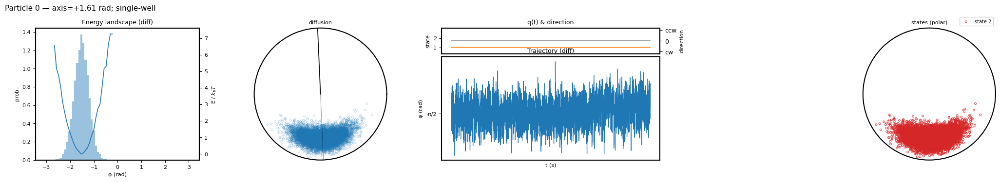

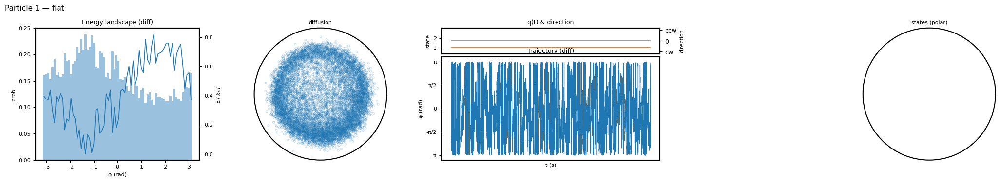

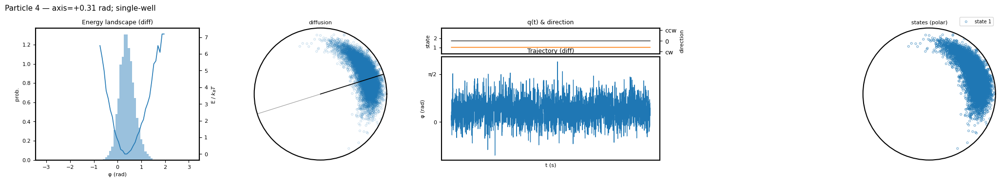

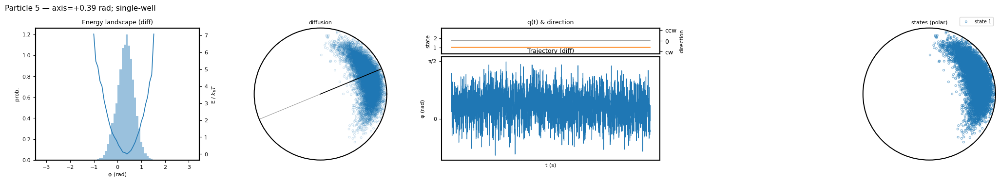

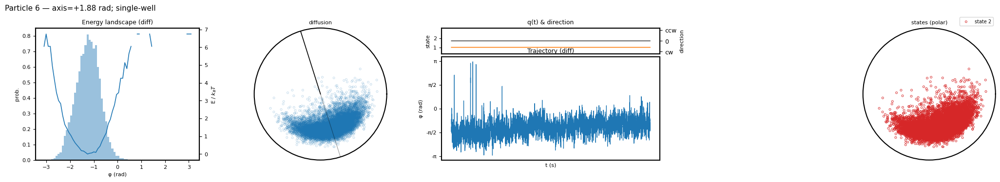

...

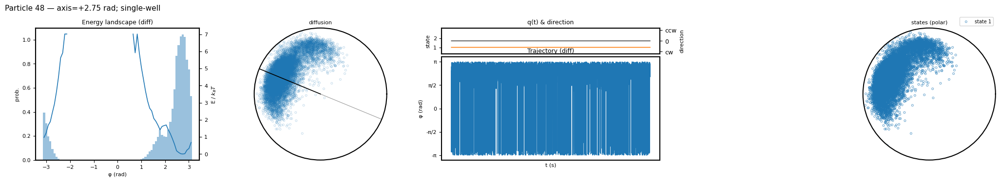

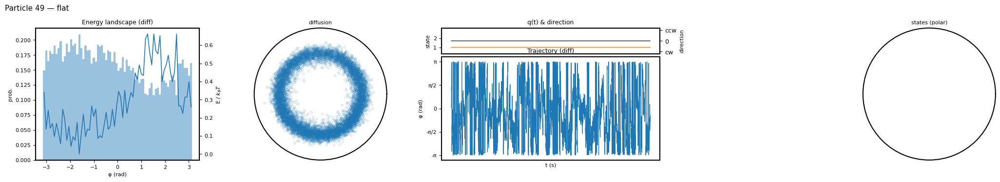

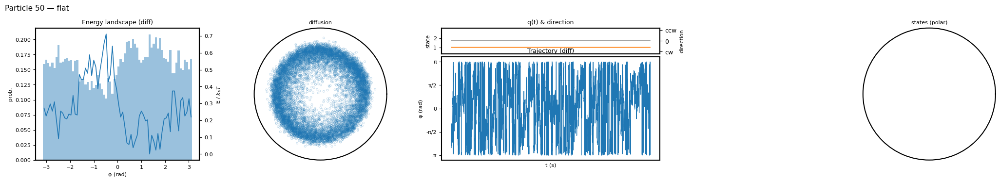

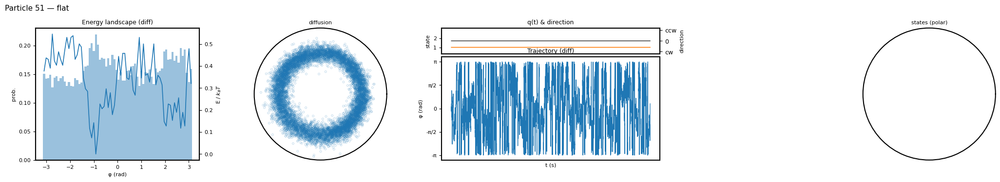

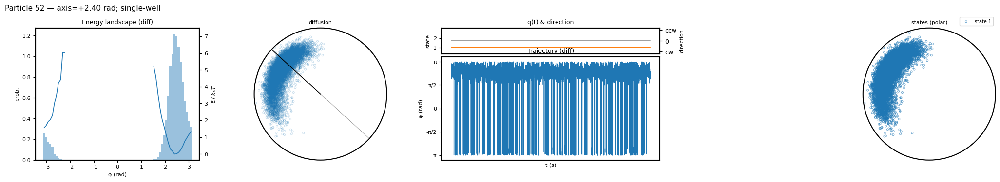

KeyboardInterrupt: 

In [11]:
%matplotlib inline

for m in m_list:
    _ = calc_state_transitions(
            m,
            particles=None,                 # None → use m.whitelist
            bins=72, sigma_bins=0.01, #1.0
            prom_rel=0.15, min_sep=np.pi/2,
            deadzone=np.deg2rad(30),
            flat_barrier_kbt=1.5,
            particle_plots=True,            # per-particle figures
            ensemble_plots=True,            # ensemble summary plots
            first_n_plots=50          # limit number of particle figures
        )

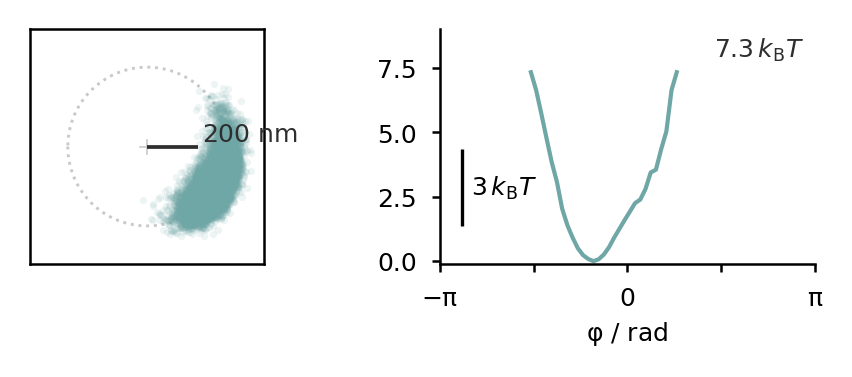

In [12]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.collections import PathCollection
from pathlib import Path


def ck_colors():
    return {
        "orange":     (215/255, 131/255,  41/255),
        "beige":      (225/255, 209/255, 180/255),
        "gold":       (226/255, 172/255,  72/255),
        "olive":      (140/255, 135/255,  59/255),
        "offwhite":   (222/255, 224/255, 213/255),
        "palecyan":   (167/255, 197/255, 197/255),
        "darkcyan":   (105/255, 155/255, 155/255),
        "lightblue":  ( 73/255, 139/255, 167/255),
        "darkblue":   ( 46/255,  89/255, 108/255),
        "darkred":    (102/255,  27/255,  35/255),
        "grey":       (0.25, 0.25, 0.25),
        "lightgrey":  (0.72, 0.72, 0.72),

        # Figure 2 rotor colors
        "target_teal":     (111/255, 166/255, 166/255),  # #6FA6A6
        "calib_warmgold":  (198/255, 161/255,  91/255),  # #C6A15B
        "free_grey":       (201/255, 201/255, 201/255),  # #C9C9C9
        "fit_darkgrey":    ( 46/255,  46/255,  46/255),  # #2E2E2E
    }


PAPER_RC = globals().get("PAPER_RC", {
    "font.family": "DejaVu Sans",
    "mathtext.fontset": "dejavusans",
    "font.size": 7,
    "axes.labelsize": 7,
    "xtick.labelsize": 6,
    "ytick.labelsize": 6,
    "figure.dpi": 300,
    "axes.linewidth": 0.6,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.size": 2.0,
    "ytick.major.size": 2.0,
})

GREY_TEXT = ck_colors()["grey"]
GREY_TEXT = "black"

def _mm(x):
    return float(x) / 25.4


def _style_ax(ax, grey=GREY_TEXT):
    for s in ax.spines.values():
        s.set_color(grey)
        s.set_linewidth(0.6)
    ax.tick_params(length=2.0, width=0.6, colors=grey)
    ax.xaxis.label.set_color(grey)
    ax.yaxis.label.set_color(grey)
    ax.grid(False)


def _style_scatter_ax(ax, cart_rlim=0.95):
    ax.set_aspect("equal")
    ax.set_xlim(-cart_rlim, cart_rlim)
    ax.set_ylim(-cart_rlim, cart_rlim)
    ax.set_xticks([])
    ax.set_yticks([])
    _style_ax(ax, GREY_TEXT)


def _style_energy_panel(
    ax,
    *,
    xlabel=r"$\varphi$ / rad",
    ylabel=None,
    xtick_fontsize=6,
    xlabel_fontsize=6,
    ylabel_fontsize=6,
    xlabel_pad=2,
):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.spines["left"].set_color(GREY_TEXT)
    ax.spines["left"].set_linewidth(0.6)
    ax.spines["bottom"].set_color(GREY_TEXT)
    ax.spines["bottom"].set_linewidth(0.6)

    ax.tick_params(axis="both", length=2.0, width=0.6, colors=GREY_TEXT, labelsize=xtick_fontsize)
    ax.set_xticks([-np.pi, -np.pi/2, 0.0, np.pi/2, np.pi])
    ax.set_xticklabels(["−π", "", "0", "", "π"], fontsize=xtick_fontsize)
    ax.set_xlabel(xlabel, color=GREY_TEXT, labelpad=xlabel_pad, fontsize=xlabel_fontsize)

    if ylabel is not None:
        ax.set_ylabel(ylabel, color=GREY_TEXT, fontsize=ylabel_fontsize)
    else:
        ax.set_ylabel("")

    ax.grid(False)


def _rasterize_point_clouds(fig):
    for ax in fig.axes:
        for coll in ax.collections:
            if isinstance(coll, PathCollection):
                coll.set_rasterized(True)


_TWOPI = 2 * np.pi


def _wrap_pi(a):
    return (np.asarray(a) + np.pi) % _TWOPI - np.pi


def _robust_axis(phi):
    phi = np.asarray(phi, float)
    return _wrap_pi(np.arctan2(np.nanmean(np.sin(phi)), np.nanmean(np.cos(phi))))


def _rotate_phi(phi, axis, target_axis_rad):
    if not np.isfinite(axis):
        axis = _robust_axis(phi)
    return _wrap_pi(np.asarray(phi) - axis + float(target_axis_rad))


def _polar_to_xy(phi, r, rnorm=0.70):
    r = np.asarray(r) if r is not None else np.ones_like(phi)
    rf = r[np.isfinite(r)]
    rmax = np.nanpercentile(rf, 99.5) if rf.size else 1.0
    if not np.isfinite(rmax) or rmax <= 0:
        rmax = 1.0
    rr = np.clip((r / rmax) * rnorm, 0.0, np.inf)
    return rr * np.cos(phi), rr * np.sin(phi), rmax


def _energy_counts_nan(phi, edges):
    counts, _ = np.histogram(phi, bins=edges, density=False)
    binw = np.diff(edges)
    N = counts.sum()

    P = np.full_like(counts, np.nan, dtype=float)
    if N > 0:
        sel = (counts > 0) & np.isfinite(counts)
        P[sel] = counts[sel] / (N * binw[sel])

    with np.errstate(divide="ignore", invalid="ignore"):
        E = -np.log(P)

    if np.isfinite(E).any():
        E -= np.nanmin(E[np.isfinite(E)])

    C = 0.5 * (edges[:-1] + edges[1:])
    return C, E


def _extract_core_simple(m, pid):
    g = (m.locs["group"].to_numpy() == int(pid))
    df = m.locs.loc[g]

    if len(df) == 0:
        raise ValueError(f"Particle {pid} not found.")

    if "phi" in df.columns:
        phi = df["phi"].to_numpy(float)
    elif {"x", "y"}.issubset(df.columns):
        phi = np.arctan2(df["y"].to_numpy(float), df["x"].to_numpy(float))
    else:
        raise RuntimeError("Cannot extract phi for particle.")

    if "rho" in df.columns:
        r = df["rho"].to_numpy(float)
    elif {"x", "y"}.issubset(df.columns):
        r = np.hypot(df["x"].to_numpy(float), df["y"].to_numpy(float))
    else:
        r = np.ones_like(phi)

    return {"phi": phi, "radii": r, "axis": _robust_axis(phi)}


def _infer_nm_per_rho_unit(m, pid, assume_particle_data_R_is_nm=True):
    pid = int(pid)

    try:
        if hasattr(m, "locs") and {"rho", "rho_nm"}.issubset(set(m.locs.columns)):
            g = (m.locs["group"].to_numpy() == pid)
            r = m.locs.loc[g, "rho"].to_numpy(float)
            rn = m.locs.loc[g, "rho_nm"].to_numpy(float)
            mask = np.isfinite(r) & np.isfinite(rn) & (r > 0)
            if np.any(mask):
                k = float(np.median(rn[mask] / r[mask]))
                if np.isfinite(k) and k > 0:
                    return k
    except Exception:
        pass

    for attr in ("pixel_size_nm", "nm_per_px", "nm_per_pixel", "nm_per_unit"):
        if hasattr(m, attr):
            try:
                k = float(getattr(m, attr))
                if np.isfinite(k) and k > 0:
                    return k
            except Exception:
                pass

    if assume_particle_data_R_is_nm and hasattr(m, "particle_data") and hasattr(m, "locs"):
        try:
            if pid in m.particle_data.index and "R" in m.particle_data.columns and "rho" in m.locs.columns:
                R_nm = float(m.particle_data.at[pid, "R"])
                if np.isfinite(R_nm) and R_nm > 0:
                    g = (m.locs["group"].to_numpy() == pid)
                    rho = m.locs.loc[g, "rho"].to_numpy(float)
                    rho = rho[np.isfinite(rho) & (rho > 0)]
                    if rho.size:
                        rho_med = float(np.median(rho))
                        k = R_nm / rho_med
                        if np.isfinite(k) and k > 0:
                            return k
        except Exception:
            pass

    raise RuntimeError("Cannot infer nm-per-rho-unit. Set nm_per_rho_unit explicitly.")


def _draw_origin_ray_nm(
    ax,
    *,
    nm_len,
    nm_per_rho_unit,
    rmax,
    rnorm,
    phi0=0.0,
    color=GREY_TEXT,
    lw=0.8,
    label=r"$200~\mathrm{nm}$",
    label_offset_pts=(2, 2),
    zorder=50,
):
    L_plot = (float(nm_len) / float(nm_per_rho_unit)) / float(rmax) * float(rnorm)
    x1 = L_plot * np.cos(float(phi0))
    y1 = L_plot * np.sin(float(phi0))

    ax.plot([0.0, x1], [0.0, y1], lw=float(lw), color=color, solid_capstyle="butt", zorder=zorder)
    ax.annotate(
        label,
        xy=(x1, y1),
        xycoords="data",
        xytext=label_offset_pts,
        textcoords="offset points",
        ha="left",
        va="bottom",
        fontsize=6,
        color=color,
        zorder=zorder,
    )


def _add_vertical_scalebar_U(
    ax,
    dU=3.0,
    label=r"$3\,k_{\mathrm{B}}T$",
    x_frac=0.06,
    y_frac=0.16,
    lw=0.8,
    fontsize=6,
    pad_pts=2,
):
    x0 = ax.get_xlim()[0] + float(x_frac) * (ax.get_xlim()[1] - ax.get_xlim()[0])
    y0 = ax.get_ylim()[0] + float(y_frac) * (ax.get_ylim()[1] - ax.get_ylim()[0])
    y1 = y0 + float(dU)
    y1 = min(y1, ax.get_ylim()[1] - 0.04 * (ax.get_ylim()[1] - ax.get_ylim()[0]))
    y0 = y1 - float(dU)

    ax.plot([x0, x0], [y0, y1], color=GREY_TEXT, lw=float(lw), solid_capstyle="butt", clip_on=False)
    ax.annotate(
        label,
        xy=(x0, 0.5 * (y0 + y1)),
        xycoords="data",
        xytext=(pad_pts, 0),
        textcoords="offset points",
        ha="left",
        va="center",
        fontsize=float(fontsize),
        color=GREY_TEXT,
    )


def _annotate_emax(
    ax,
    E,
    *,
    fmt=r"$%.1f\,k_{\mathrm{B}}T$",
    loc="upper right",
    fontsize=6,
    color=GREY_TEXT,
    pad=0.03,
):
    E = np.asarray(E, float)
    if not np.isfinite(E).any():
        return
    emax = float(np.nanmax(E[np.isfinite(E)]))

    if loc == "upper right":
        x, y, ha, va = 1.0 - pad, 1.0 - pad, "right", "top"
    elif loc == "upper left":
        x, y, ha, va = pad, 1.0 - pad, "left", "top"
    elif loc == "lower right":
        x, y, ha, va = 1.0 - pad, pad, "right", "bottom"
    else:
        x, y, ha, va = pad, pad, "left", "bottom"

    ax.text(x, y, fmt % emax, transform=ax.transAxes, ha=ha, va=va, fontsize=fontsize, color=color)


def plot_single_scatter_plus_energy(
    m,
    pid,
    *,
    align_deg=37.0,
    extra_deg=0.0,
    color_key="target_teal",

    fig_w_mm=70,
    fig_h_mm=34,
    left=0.08,
    right=0.985,
    top=0.92,
    bottom=0.20,
    wspace=0.28,

    cartesian_rlim=0.82,
    rnorm=0.70,
    s_pts=3,
    alpha_pts=0.12,

    draw_ref_ring=True,
    ref_ring_ls=":",
    draw_scatter_ray_scalebar=True,
    nm_scalebar=200.0,
    nm_per_rho_unit=None,

    energy_bins=72,
    energy_lw=1.0,
    shared_energy_ylim=(-0.2, 9.0),
    add_energy_scalebar=True,
    energy_scalebar_dU=3.0,
    energy_scalebar_label=r"$3\,k_{\mathrm{B}}T$",
    annotate_emax=True,
    emax_fmt=r"$%.1f\,k_{\mathrm{B}}T$",

    panel_title=None,
    rasterize=True,
):
    """
    One rotor only:
        left  = localization scatter
        right = diffusion-derived energy landscape

    The energy panel is snapped to the same square box size as the scatter panel.
    """

    C = ck_colors()
    col = C[color_key]

    if not ((m.locs["group"].to_numpy() == int(pid)).any()):
        raise ValueError(f"Particle {pid} missing in {Path(str(m.path)).name}")

    core = _extract_core_simple(m, int(pid))
    phi = np.asarray(core["phi"], float)
    r = np.asarray(core.get("radii", np.ones_like(phi)), float)
    axis = float(core.get("axis", np.nan))

    phi_rot = _rotate_phi(phi, axis, np.deg2rad(float(align_deg) + float(extra_deg)))
    x, y, rmax = _polar_to_xy(phi_rot, r, rnorm=float(rnorm))

    edges = np.linspace(-np.pi, np.pi, int(energy_bins) + 1)
    Cphi, E = _energy_counts_nan(phi_rot, edges)

    with mpl.rc_context(PAPER_RC):
        fig = plt.figure(figsize=(_mm(fig_w_mm), _mm(fig_h_mm)))
        gs = fig.add_gridspec(
            1,
            2,
            left=float(left),
            right=float(right),
            top=float(top),
            bottom=float(bottom),
            wspace=float(wspace),
        )

        axS = fig.add_subplot(gs[0, 0])
        axE = fig.add_subplot(gs[0, 1])

        # ---------------------------
        # Scatter panel
        # ---------------------------
        _style_scatter_ax(axS, cart_rlim=float(cartesian_rlim))
        axS.scatter(x, y, s=float(s_pts), lw=0, fc=col, alpha=float(alpha_pts))

        s = 0.06 * float(cartesian_rlim)
        axS.plot([-s, s], [0, 0], color=C["free_grey"], lw=0.4, zorder=-1000)
        axS.plot([0, 0], [-s, s], color=C["free_grey"], lw=0.4, zorder=-1000)

        if draw_ref_ring:
            R_val = np.nan
            if hasattr(m, "particle_data") and hasattr(m.particle_data, "index") and int(pid) in m.particle_data.index:
                try:
                    R_val = float(m.particle_data.at[int(pid), "R"])
                except Exception:
                    R_val = np.nan

            if np.isfinite(R_val) and np.isfinite(rmax) and rmax > 0:
                th = np.linspace(-np.pi, np.pi, 361)
                R_plot = (R_val / rmax) * float(rnorm)
                axS.plot(
                    R_plot * np.cos(th),
                    R_plot * np.sin(th),
                    color=C["free_grey"],
                    lw=0.7,
                    ls=ref_ring_ls,
                    zorder=-1000,
                )

        if draw_scatter_ray_scalebar:
            k = float(nm_per_rho_unit) if nm_per_rho_unit is not None else _infer_nm_per_rho_unit(m, pid)
            _draw_origin_ray_nm(
                axS,
                nm_len=float(nm_scalebar),
                nm_per_rho_unit=float(k),
                rmax=float(rmax),
                rnorm=float(rnorm),
                phi0=0.0,
                color=C["fit_darkgrey"],
                lw=0.9,
                label=f"${int(nm_scalebar)}"+r"~\mathrm{nm}$",
                label_offset_pts=(1, 0),
            )

        # ---------------------------
        # Energy panel
        # ---------------------------
        axE.plot(Cphi, E, lw=float(energy_lw), color=col)
        axE.set_xlim(-np.pi, np.pi)
        axE.set_ylim(float(shared_energy_ylim[0]), float(shared_energy_ylim[1]))
        _style_energy_panel(
            axE,
            xlabel=r"$\mathrm{\varphi}$ / rad",
            ylabel=None,
            xtick_fontsize=6,
            xlabel_fontsize=6,
        )

        if add_energy_scalebar:
            _add_vertical_scalebar_U(
                axE,
                dU=float(energy_scalebar_dU),
                label=str(energy_scalebar_label),
            )

        if annotate_emax:
            _annotate_emax(
                axE,
                E,
                fmt=str(emax_fmt),
                loc="upper right",
                fontsize=6,
                color=C["fit_darkgrey"],
            )

        if panel_title is not None:
            fig.text(left, top + 0.01, str(panel_title), ha="left", va="bottom", fontsize=7, color=GREY_TEXT)

        # ---------------------------
        # Force same square panel size
        # ---------------------------
        fig.canvas.draw()

        pS = axS.get_position()
        pE = axE.get_position()

        side = min(pS.width, pS.height)
        axS.set_position([pS.x0, pS.y0 + 0.5 * (pS.height - side), side, side])

        pS = axS.get_position()
        side = pS.height
        axE.set_position([pE.x0, pS.y0, side, side])

        if rasterize:
            _rasterize_point_clouds(fig)

        return fig, {"scatter_ax": axS, "energy_ax": axE, "phi_rot": phi_rot, "C": Cphi, "E": E}


# Example call:
fig, out = plot_single_scatter_plus_energy(
    m_list[0],
    pid=46,
    align_deg=-30,
    extra_deg=0,
    color_key="target_teal",   # or "calib_warmgold", "free_grey", etc.
    fig_w_mm=80,
    fig_h_mm=50,
    nm_scalebar=200.0,
    shared_energy_ylim=(-0.1, 9.0),
    panel_title=None,
)
plt.show()

save_figure(
    fig,
    name="Fig1_diffusive_energylandscape_L2ss",
    stator_variant="",
    save_directory=r"R:\_06_Umbrella_Sampling\02_Figures\Figure_1",
)